# 03 — Random Forest
### Telco Customer Churn Prediction

A Random Forest averages many decorrelated trees. It tests whether reducing the variance of a single tree gives better churn ranking than the linear model.

**Shared protocol** (identical in notebooks 01–06):
- Same training set (3,944 customers) and same 5 stratified folds (`random_state = 34`).
- Same preprocessing (`FINAL_PREP_CONFIG` from notebook 00): binary add-ons, one-hot `InternetService` and `Contract`, binary `Dependents`/`PaperlessBilling`, standardised `log(1 + tenure)` and `MonthlyCharges`.
- Same tuning procedure: **nested cross-validation** (inner 5-fold grid search, outer 5-fold evaluation), scored by PR-AUC.
- Unweighted classes; class imbalance is handled at the decision threshold (notebook 08) and examined in notebook 07.
- The test set is **not used**. The nested out-of-fold predictions saved at the end are used for comparison and threshold selection in notebook 08.

## 1. How the Algorithm Works

A Random Forest grows many decision trees. Each tree is trained on a **bootstrap sample** (random rows with replacement) and considers only a random subset of features (`max_features`) at each split. The forest's probability is the average of the trees' probabilities.

This is **bagging** (bootstrap aggregating). Averaging many high-variance, weakly correlated trees reduces variance while keeping the trees' low bias.

## 2. Relevance, Assumptions and Limitations

- **Relevance:** strong accuracy on tabular data; captures non-linearity and interactions; much less prone to overfitting than one tree.
- **Assumptions:** none about the functional form.
- **Limitations:**
  - low interpretability (hundreds of trees);
  - impurity-based importances are biased toward features with many split points;
  - larger model size and training time.

## 3. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's shared src/ package importable, wherever Jupyter was started
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_preprocessing.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.ensemble import RandomForestClassifier
from src.data_preprocessing import FINAL_PREP_CONFIG, RANDOM_STATE, build_pipeline, load_raw_data, split_train_test
from src.evaluation import (cv_scores, final_search, fold_metrics, mean_std_table, nested_summary_row, run_nested_cv,
                            save_results, summarise_cv)
from src.visualization import plot_confusion, plot_permutation_importance, plot_reliability, save_figure, set_style

set_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

df = load_raw_data()                                       # validated raw data (read-only)
X_train, X_test, y_train, y_test = split_train_test(df)   # the project's single stratified 80/20 split
del X_test, y_test                                        # the test set is not used in this notebook
print(f"Training set: {X_train.shape[0]:,} customers, {int(y_train.sum()):,} churners ({y_train.mean():.2%})")
print("Preprocessing configuration (from notebook 00):", FINAL_PREP_CONFIG)

Training set: 3,944 customers, 1,053 churners (26.70%)
Preprocessing configuration (from notebook 00): {'contract': 'onehot', 'addons': 'binary', 'tenure': 'log'}


In [2]:
MODEL_NAME = "Random Forest"
SLUG = "03_random_forest"
INTERPRETABILITY_RANK = 3  # 1 = most interpretable

## 4. Preprocessing Pipeline

The shared pipeline is used. Scaling and the log transform do not affect tree splits (Section 4 of notebook 02).

In [3]:
ESTIMATOR = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)


pipeline = build_pipeline(ESTIMATOR, **FINAL_PREP_CONFIG)
print("Pipeline steps:", [name for name, _ in pipeline.steps])
print("Transformers:", [(name, cols) for name, _, cols in pipeline.named_steps["preprocess"].transformers])
print("Model:", ESTIMATOR)

Pipeline steps: ['preprocess', 'model']
Transformers: [('binary', ['Dependents', 'PaperlessBilling']), ('addons', ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']), ('internet', ['InternetService']), ('contract', ['Contract']), ('tenure_log', ['tenure']), ('numeric', ['MonthlyCharges'])]
Model: RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=34)


## 5. Baseline Configuration

The baseline uses 300 trees with default settings: unlimited depth, single-customer leaves, `max_features='sqrt'`.

In [4]:
BASELINE_ESTIMATOR = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)


baseline_raw = cv_scores(build_pipeline(BASELINE_ESTIMATOR, **FINAL_PREP_CONFIG), X_train, y_train)
baseline = summarise_cv(baseline_raw)
display(mean_std_table(pd.DataFrame([baseline], index=["Baseline (5-fold CV, threshold 0.5)"])))
gap = {m: baseline[f"{m} train"] - baseline[f"{m} mean"] for m in ["F1", "ROC-AUC", "PR-AUC"]}
print("Train - validation gap:", {k: round(v, 3) for k, v in gap.items()})

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
"Baseline (5-fold CV, threshold 0.5)",0.770 ± 0.008,0.590 ± 0.024,0.466 ± 0.032,0.520 ± 0.018,0.810 ± 0.005,0.603 ± 0.015


Train - validation gap: {'F1': np.float64(0.468), 'ROC-AUC': np.float64(0.19), 'PR-AUC': np.float64(0.396)}


**Interpretation.**
- The default forest of 300 fully grown trees reaches validation PR-AUC **0.603** and ROC-AUC 0.810.
- Its training-fold PR-AUC is 0.396 higher, so it still **overfits**.
- Averaging limits the damage compared with a single tree (0.379). But single-customer leaves are too fine-grained for a target as noisy as churn.

## 6. Hyperparameter Tuning Methodology


Hyperparameters are tuned with **nested cross-validation**:
- the 5 outer folds hold out 20% of the training set in turn;
- on the other 80%, a full grid search with its own inner 5-fold CV chooses the configuration;
- the chosen configuration, refitted on that 80%, predicts the held-out outer fold.

The outer-fold labels never influence tuning, so the resulting out-of-fold (OOF) probabilities are honest estimates of how the *whole hyperparameter-tuning procedure* performs on unseen customers. (The preprocessing configuration was fixed beforehand in notebook 00 using the same training folds; notebook 08, Section 6 shows that re-selecting it inside the nested loop changes the estimate only marginally.) A simpler "tune on everything, then cross-validate" design would reuse the same labels for selection and evaluation, which makes the estimates optimistic.

| Hyperparameter | Values | Role |
|---|---|---|
| `n_estimators` | 300 (fixed) | More trees only stabilise the average; they do not cause overfitting |
| `max_depth` | 6, 10, None | Depth of each tree |
| `min_samples_leaf` | 5, 15, 30, 50 | Smoothness of each tree's leaf estimates |
| `max_features` | 0.2, sqrt, 0.5 | Features considered per split (2, 3 or 6 of the 12 encoded features); fewer = more decorrelated trees (range extended after a first run selected the boundary value) |

In [5]:
PARAM_GRID = {"model__max_depth": [6, 10, None], "model__min_samples_leaf": [5, 15, 30, 50], "model__max_features": [0.2, "sqrt", 0.5]}


n_configurations = int(np.prod([len(v) for v in PARAM_GRID.values()]))
print(f"{n_configurations} configurations x 5 inner folds x 5 outer folds = {n_configurations * 25} fits "
      f"(+ {5} refits) in the nested CV")

36 configurations x 5 inner folds x 5 outer folds = 900 fits (+ 5 refits) in the nested CV


## 7. Nested Cross-Validation Results

In [6]:
nested = run_nested_cv(ESTIMATOR, PARAM_GRID, X_train, y_train, FINAL_PREP_CONFIG, compute_importance=True)
print(f"Nested CV wall time: {nested['seconds']:.1f} s\n")
display(nested["folds"].round(4))
print("Mean ± std over the 5 outer folds (accuracy, precision, recall and F1 at the reference threshold 0.5):")
display(pd.DataFrame([nested_summary_row(nested)], index=[MODEL_NAME]))
print("Hyperparameters chosen by the inner search in each outer fold:")
for fold, params in enumerate(nested["params"], start=1):
    print(f"  fold {fold}: {params}")

Nested CV wall time: 43.6 s



,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,log_loss
fold,,,,,,,,
1,0.7972,0.6457,0.5355,0.5855,0.8471,0.6536,0.1373,0.4168
2,0.8023,0.6950,0.4645,0.5568,0.8670,0.7100,0.1290,0.4028
3,0.7883,0.6279,0.5118,0.5640,0.8244,0.6551,0.1417,0.4414
4,0.7833,0.6423,0.4190,0.5072,0.8394,0.6515,0.1379,0.4247
5,0.7995,0.6857,0.4571,0.5486,0.8458,0.6464,0.1378,0.4210


Mean ± std over the 5 outer folds (accuracy, precision, recall and F1 at the reference threshold 0.5):


,PR-AUC,ROC-AUC,Brier score,Accuracy,Precision,Recall,F1
Random Forest,0.663 ± 0.024,0.845 ± 0.014,0.137 ± 0.004,0.794 ± 0.007,0.659 ± 0.026,0.478 ± 0.041,0.552 ± 0.026


Hyperparameters chosen by the inner search in each outer fold:
  fold 1: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 15}
  fold 2: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 15}
  fold 3: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 15}
  fold 4: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 30}
  fold 5: {'max_depth': None, 'max_features': 0.2, 'min_samples_leaf': 15}


**Interpretation.**
- Nested **PR-AUC 0.663 ± 0.024** and **ROC-AUC 0.845 ± 0.014**: a large improvement over the default (0.603), and within 0.003 of Logistic Regression.
- The decisive setting is again **leaf size**: 15 customers per leaf in four of five folds, 30 in one.
- `max_features` was extended to include 0.2 after the first run selected the lower boundary (`sqrt`). With the wider range, `sqrt` (3 of 12 features) is chosen in four folds and 0.2 in one, so the optimum lies inside the range.
- The non-nested search score is 0.004 higher than the nested estimate, a small optimism from choosing the best of 36 configurations.

## 8. Final Hyperparameters

The same grid search is run once on the full training set. Its refitted pipeline is this algorithm's final candidate, which notebook 09 evaluates if it is selected. Comparing the best search score with the nested estimate shows the optimism of a non-nested search.

In [7]:
search = final_search(ESTIMATOR, PARAM_GRID, X_train, y_train, FINAL_PREP_CONFIG)
final_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
final_summary = pd.Series({
    "best hyperparameters": final_params,
    "search CV PR-AUC (best of grid)": round(search.best_score_, 4),
    "nested CV PR-AUC": round(nested["folds"]["pr_auc"].mean(), 4),
    "optimism of the search score": round(search.best_score_ - nested["folds"]["pr_auc"].mean(), 4),
    "train-fold PR-AUC of best configuration": round(search.cv_results_["mean_train_score"][search.best_index_], 4),
})
display(final_summary.to_frame("value"))

,value
best hyperparameters,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 15}"
search CV PR-AUC (best of grid),0.6674
nested CV PR-AUC,0.6633
optimism of the search score,0.0041
train-fold PR-AUC of best configuration,0.7251


## 9. Diagnostics (Nested Out-of-Fold Predictions)

The confusion matrix uses the reference threshold of 0.5 only; the operating threshold is chosen in notebook 08. The reliability diagram checks whether predicted probabilities match observed churn rates (**calibration**), and the precision-recall curve shows the ranking quality across all thresholds (**discrimination**).

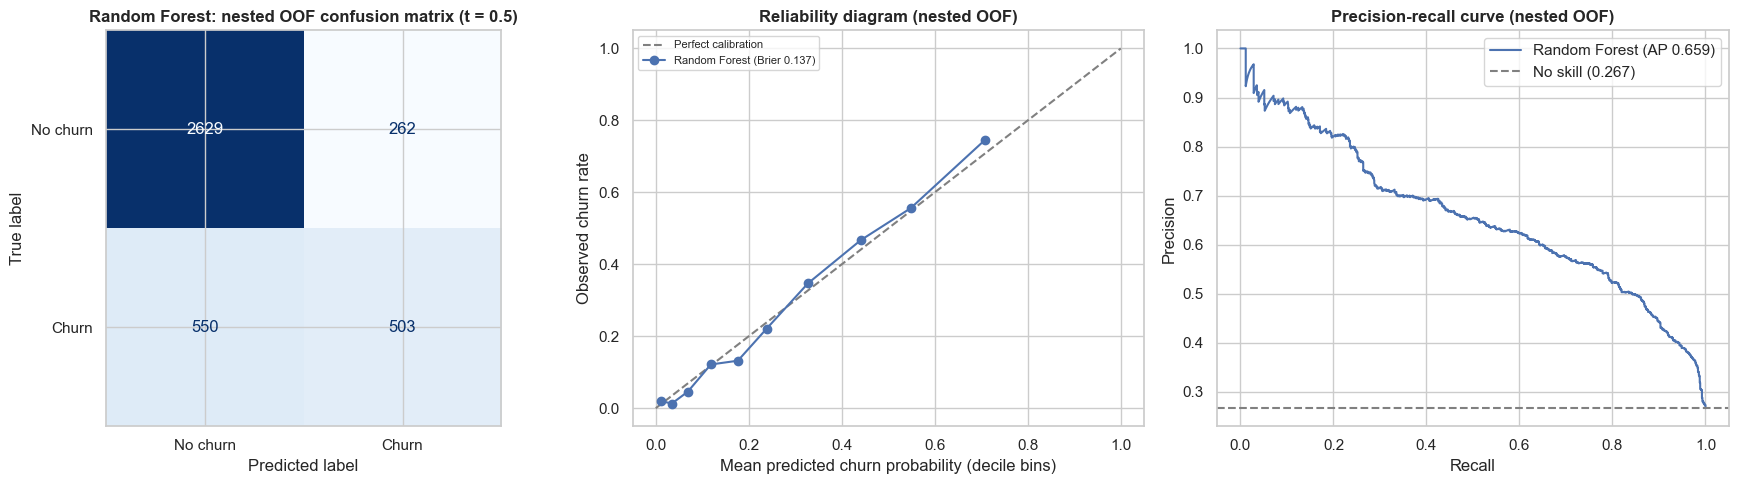

In [8]:
oof = nested["oof"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_confusion(axes[0], y_train, (oof >= 0.5).astype(int), f"{MODEL_NAME}: nested OOF confusion matrix (t = 0.5)")
plot_reliability(axes[1], y_train, {MODEL_NAME: oof}, "Reliability diagram (nested OOF)")
prec, rec, _ = precision_recall_curve(y_train, oof)
axes[2].plot(rec, prec, label=f"{MODEL_NAME} (AP {average_precision_score(y_train, oof):.3f})")
axes[2].axhline(y_train.mean(), linestyle="--", color="gray", label=f"No skill ({y_train.mean():.3f})")
axes[2].set_title("Precision-recall curve (nested OOF)")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
plt.tight_layout()
save_figure(fig, f"{SLUG}_diagnostics")
plt.show()

**Interpretation.**
- **At t = 0.5:** the forest flags fewer customers than Logistic Regression. It catches 503 churners and misses 550, while flagging 262 non-churners.
- **Reliability diagram:** close to the diagonal (Brier 0.137). Averaged leaf frequencies produce reasonably calibrated probabilities here.
- **Precision-recall curve:** almost indistinguishable from Logistic Regression's (pooled AP 0.659).

## 10. Model Interpretation

**Permutation importance** is the drop in PR-AUC when one original feature's values are shuffled. It is computed inside the nested CV, on each outer validation fold, for the model tuned and fitted without that fold, so it inherits no selection leakage. Shuffling one of two features that share information understates both. Importance describes what the *model* relies on; it is not a causal effect.

The forest's **impurity-based importance** (computed on training data) is shown alongside for comparison. It tends to favour continuous features.

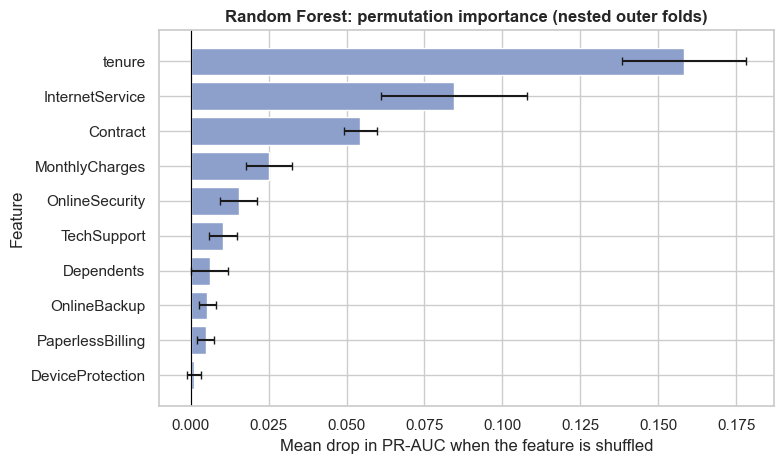

,mean,std
feature,,
tenure,0.1582,0.0200
InternetService,0.0846,0.0234
Contract,0.0544,0.0052
MonthlyCharges,0.0250,0.0074
OnlineSecurity,0.0153,0.0060
TechSupport,0.0103,0.0044
Dependents,0.0060,0.0061
OnlineBackup,0.0053,0.0028
PaperlessBilling,0.0047,0.0028


In [9]:
fig, ax = plt.subplots(figsize=(8, 4.8))
perm_summary = plot_permutation_importance(ax, nested["importance"],
                                           f"{MODEL_NAME}: permutation importance (nested outer folds)")
plt.tight_layout()
save_figure(fig, f"{SLUG}_permutation_importance")
plt.show()
display(perm_summary.sort_values("mean", ascending=False).round(4))

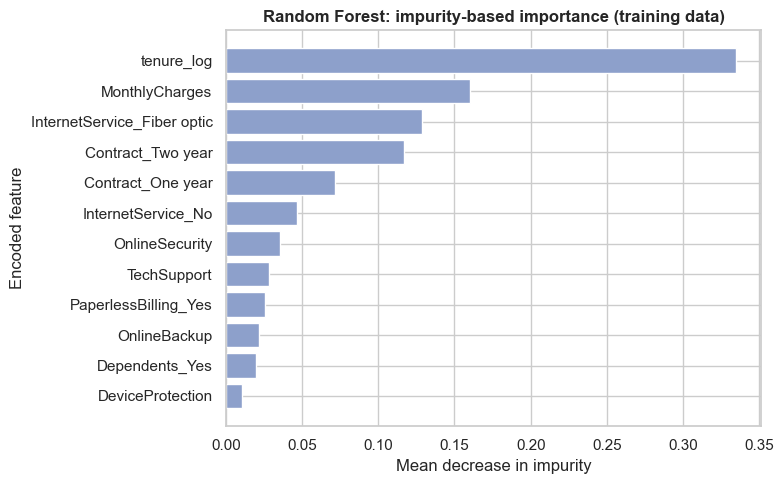

In [10]:
final_pipeline = search.best_estimator_
impurity = pd.Series(final_pipeline.named_steps["model"].feature_importances_,
                     index=final_pipeline.named_steps["preprocess"].get_feature_names_out()).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(impurity.index, impurity.values, color="#8DA0CB")
ax.set_title("Random Forest: impurity-based importance (training data)")
ax.set_xlabel("Mean decrease in impurity")
ax.set_ylabel("Encoded feature")
plt.tight_layout()
plt.show()

**Interpretation.**
- **Permutation importance:** `tenure` (0.158) is again dominant, followed by `InternetService` (0.085), `Contract` (0.054) and `MonthlyCharges` (0.025).
- Compared with Logistic Regression, the forest relies more on internet service and less on price. The two features carry overlapping information (η = 0.905 in notebook 00), and the forest's splits pick up the categorical version.
- **Impurity-based importance** ranks the continuous features much higher. This illustrates its known bias toward features with many possible split points, which is why permutation importance on held-out folds is the more reliable measure.

## 11. Strengths, Weaknesses and Conclusion

**Strengths**
- Ranking equivalent to Logistic Regression (PR-AUC 0.663 vs 0.666).
- Reasonable calibration.
- Robust to non-linearity and interactions.

**Weaknesses**
- Still a train–validation gap (training-fold PR-AUC 0.725).
- 300 trees cannot be read directly.
- Slower to tune (about 37 s for the nested CV vs 4 s for Logistic Regression).

**Conclusion:** bagging fixes the single tree's variance problem, but it does not find structure that the linear model with log-tenure misses. Notebook 04 tests boosting, which reduces bias rather than variance.

### Saving the training-stage results

The nested OOF predictions, fold metrics, permutation importances and the final (training-set) pipeline are stored in `reports/cv_results/` for the comparison in notebook 08.

In [11]:
payload = {
    "name": MODEL_NAME, "slug": SLUG, "oof": nested["oof"], "folds": nested["folds"], "params": nested["params"],
    "importance": nested["importance"], "seconds": nested["seconds"], "baseline": baseline,
    "final_params": final_params, "final_search_score": search.best_score_,
    "final_train_score": search.cv_results_["mean_train_score"][search.best_index_],
    "final_pipeline": search.best_estimator_, "grid": PARAM_GRID, "prep_config": FINAL_PREP_CONFIG,
    "y_index": y_train.index.to_numpy(), "interpretability_rank": INTERPRETABILITY_RANK,
}
print("Saved:", save_results(SLUG, payload).relative_to(PROJECT_ROOT))

Saved: reports\cv_results\03_random_forest.joblib
